---
title: "Correlación canónica y análisis factorial"
subtitle: "Ejemplos y actividad con datos de vinos"
author: "Mateo Flores"
date: "2026-10-26"
lang: es
format:
  html:
    theme: cosmo
    toc: true
    toc-depth: 2
    code-fold: true
    code-summary: "Ver código"
    embed-resources: true
    df-print: html
execute:
  warning: false
  error: false
---



In [1]:
# Bibliotecas necesarias
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.datasets import load_iris, load_breast_cancer, load_wine
from sklearn.preprocessing import StandardScaler
from sklearn.decomposition import FactorAnalysis, PCA
from sklearn.cross_decomposition import CCA
from sklearn.linear_model import LogisticRegression, LinearRegression
from sklearn.model_selection import train_test_split
from sklearn.metrics import accuracy_score, r2_score, roc_auc_score

import statsmodels.api as sm
from scipy import stats

%matplotlib inline
sns.set_style('whitegrid')
from IPython.display import display
plt.rcParams["figure.dpi"] = 120
pd.set_option("display.precision", 4)

## Ejemplo 1. Correlación canónica con Iris

La correlación canónica combina las variables de cada grupo para encontrar la relación más alta entre ambos. En el ejemplo, un grupo contiene medidas de los sépalos y el otro de los pétalos.

In [2]:
# ============================================================
# EJEMPLO 1: ANÁLISIS DE CORRELACIÓN CANÓNICA (CCA)
# ============================================================

# Dataset Iris: medimos dos conjuntos de variables
iris = load_iris()
df_iris = pd.DataFrame(iris.data, columns=iris.feature_names)
df_iris.columns = ['Long_Sepalo', 'Ancho_Sepalo', 'Long_Petalo', 'Ancho_Petalo']

# Conjunto X: sépalos. Conjunto Y: pétalos
X_cca = df_iris[['Long_Sepalo', 'Ancho_Sepalo']].values
Y_cca = df_iris[['Long_Petalo', 'Ancho_Petalo']].values

print("Conjunto X (sépalos):", X_cca.shape)
print("Conjunto Y (pétalos):", Y_cca.shape)
print("\nPrimeras filas:")
df_iris.head()

Conjunto X (sépalos): (150, 2)
Conjunto Y (pétalos): (150, 2)

Primeras filas:


,Long_Sepalo,Ancho_Sepalo,Long_Petalo,Ancho_Petalo
0,5.1,3.5,1.4,0.2
1,4.9,3.0,1.4,0.2
2,4.7,3.2,1.3,0.2
3,4.6,3.1,1.5,0.2
4,5.0,3.6,1.4,0.2


In [3]:
# Estandarizar antes de CCA
scaler = StandardScaler()
X_cca_std = scaler.fit_transform(X_cca)
Y_cca_std = scaler.fit_transform(Y_cca)

# Ajustar CCA con 2 componentes
cca = CCA(n_components=2)
U, V = cca.fit_transform(X_cca_std, Y_cca_std)

# Correlaciones canónicas
rho = [np.corrcoef(U[:, i], V[:, i])[0, 1] for i in range(2)]
print("Correlaciones canónicas:")
for i, r in enumerate(rho):
    print(f"  ρ_{i+1} = {r:.4f}  (ρ² = {r**2:.4f})")

Correlaciones canónicas:
  ρ_1 = 0.9410  (ρ² = 0.8854)
  ρ_2 = 0.1239  (ρ² = 0.0154)


In [4]:
# Pesos canónicos (coeficientes)
pesos_X = pd.DataFrame(cca.x_weights_, 
                        index=['Long_Sepalo', 'Ancho_Sepalo'],
                        columns=['U1', 'U2'])
pesos_Y = pd.DataFrame(cca.y_weights_,
                        index=['Long_Petalo', 'Ancho_Petalo'],
                        columns=['V1', 'V2'])

print("Pesos canónicos para X (sépalos):")
print(pesos_X.round(4))
print("\nPesos canónicos para Y (pétalos):")
print(pesos_Y.round(4))

# Cargas canónicas (correlación entre variable original y variable canónica)
cargas_X = pd.DataFrame(
    [np.corrcoef(X_cca_std[:, j], U[:, i])[0, 1] 
     for i in range(2) for j in range(2)],
    index=['U1-Long_Sepalo', 'U1-Ancho_Sepalo', 'U2-Long_Sepalo', 'U2-Ancho_Sepalo'],
    columns=['Carga']
)
print("\nCargas canónicas para X:")
print(cargas_X.round(4))

Pesos canónicos para X (sépalos):
                  U1      U2
Long_Sepalo   0.9217  0.3880
Ancho_Sepalo -0.3880  0.9217

Pesos canónicos para Y (pétalos):
                  V1      V2
Long_Petalo   0.9430  0.3327
Ancho_Petalo -0.3327  0.9430

Cargas canónicas para X:
                  Carga
U1-Long_Sepalo   0.9290
U1-Ancho_Sepalo -0.4767
U2-Long_Sepalo   0.3701
U2-Ancho_Sepalo  0.8791


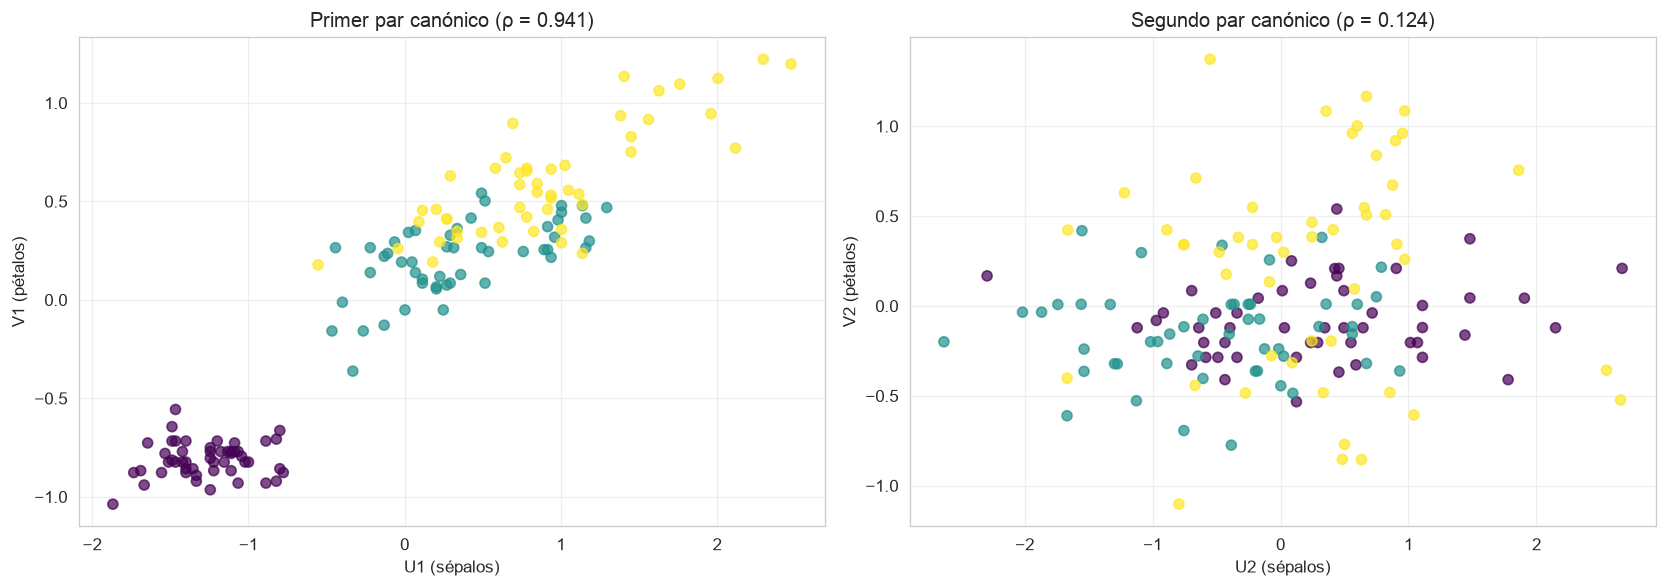

In [5]:
# Scatter de las variables canónicas
fig, axes = plt.subplots(1, 2, figsize=(14, 5))

# Par canónico 1
axes[0].scatter(U[:, 0], V[:, 0], c=iris.target, cmap='viridis', alpha=0.7)
axes[0].set_xlabel('U1 (sépalos)')
axes[0].set_ylabel('V1 (pétalos)')
axes[0].set_title(f'Primer par canónico (ρ = {rho[0]:.3f})')
axes[0].grid(True, alpha=0.3)

# Par canónico 2
axes[1].scatter(U[:, 1], V[:, 1], c=iris.target, cmap='viridis', alpha=0.7)
axes[1].set_xlabel('U2 (sépalos)')
axes[1].set_ylabel('V2 (pétalos)')
axes[1].set_title(f'Segundo par canónico (ρ = {rho[1]:.3f})')
axes[1].grid(True, alpha=0.3)

plt.tight_layout()
plt.show()

## Ejemplo 2. Análisis factorial

El análisis factorial resume variables relacionadas en factores que no se miden directamente. Las cargas indican qué tanto se relaciona cada medición con un factor. Una carga cercana a 1 o a −1 indica una relación fuerte.

In [6]:
# ============================================================
# PARTE 2: ANÁLISIS FACTORIAL (AF)
# ============================================================

# Dataset Breast Cancer: 30 variables correlacionadas
data_bc = load_breast_cancer()
X_bc = pd.DataFrame(data_bc.data, columns=data_bc.feature_names)
y_bc = data_bc.target

print(f"Forma del dataset: {X_bc.shape}")
print(f"Variables: {X_bc.shape[1]}")
print(f"\nPrimeras variables:")
print(list(X_bc.columns[:10]))

Forma del dataset: (569, 30)
Variables: 30

Primeras variables:
['mean radius', 'mean texture', 'mean perimeter', 'mean area', 'mean smoothness', 'mean compactness', 'mean concavity', 'mean concave points', 'mean symmetry', 'mean fractal dimension']


In [7]:
# Seleccionar 10 variables representativas (evitar multicolinealidad extrema)
vars_fa = ['mean radius', 'mean texture', 'mean perimeter', 
           'mean area', 'mean smoothness', 'mean compactness',
           'mean concavity', 'mean concave points',
           'mean symmetry', 'mean fractal dimension']

X_fa = X_bc[vars_fa].values
X_fa_std = StandardScaler().fit_transform(X_fa)

print(f"Variables seleccionadas: {len(vars_fa)}")
print(f"Forma: {X_fa_std.shape}")

Variables seleccionadas: 10
Forma: (569, 10)


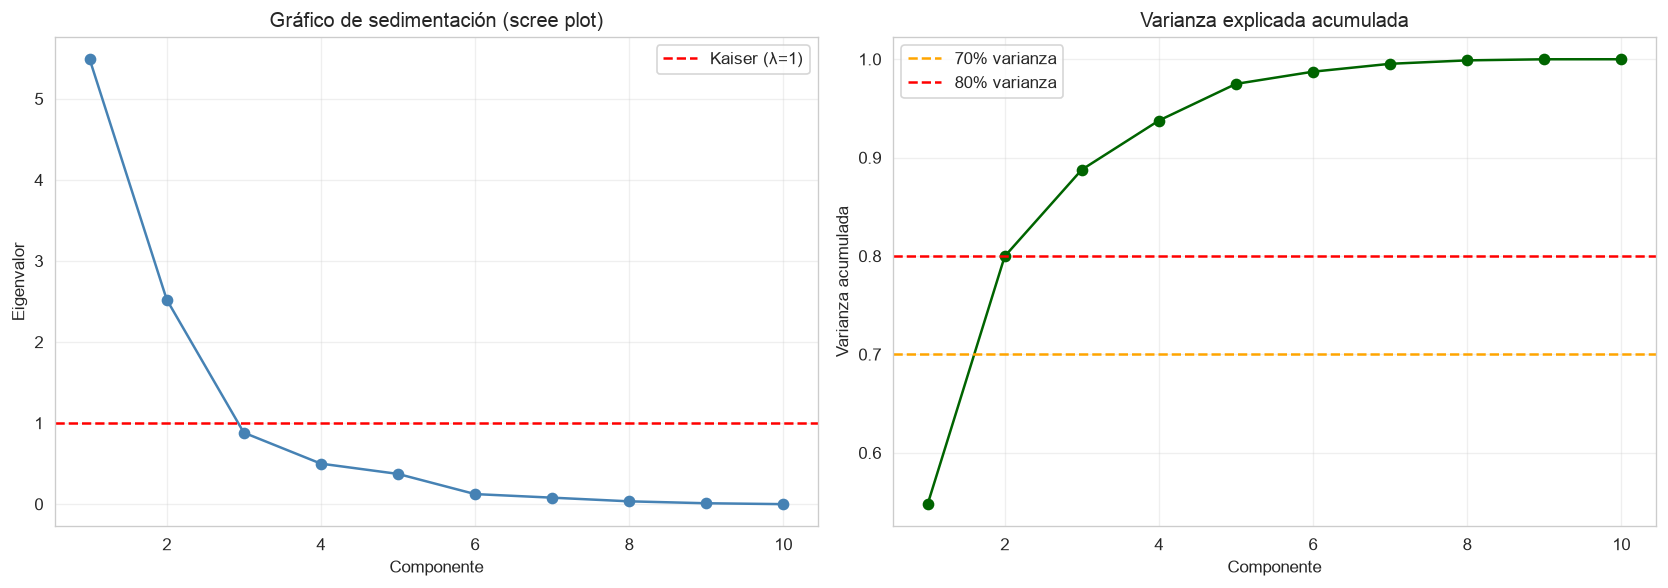


Factores con eigenvalor > 1: 2
Varianza acumulada con 2 factores: 0.800


In [8]:
# Gráfico de sedimentación (scree plot)
pca_temp = PCA()
pca_temp.fit(X_fa_std)
eigenvalues = pca_temp.explained_variance_
varianza_acum = np.cumsum(pca_temp.explained_variance_ratio_)

fig, axes = plt.subplots(1, 2, figsize=(14, 5))

# Scree plot
axes[0].plot(range(1, len(eigenvalues) + 1), eigenvalues, 'o-', color='steelblue')
axes[0].axhline(y=1, color='r', linestyle='--', label='Kaiser (λ=1)')
axes[0].set_xlabel('Componente')
axes[0].set_ylabel('Eigenvalor')
axes[0].set_title('Gráfico de sedimentación (scree plot)')
axes[0].legend()
axes[0].grid(True, alpha=0.3)

# Varianza acumulada
axes[1].plot(range(1, len(varianza_acum) + 1), varianza_acum, 'o-', color='darkgreen')
axes[1].axhline(y=0.7, color='orange', linestyle='--', label='70% varianza')
axes[1].axhline(y=0.8, color='red', linestyle='--', label='80% varianza')
axes[1].set_xlabel('Componente')
axes[1].set_ylabel('Varianza acumulada')
axes[1].set_title('Varianza explicada acumulada')
axes[1].legend()
axes[1].grid(True, alpha=0.3)

plt.tight_layout()
plt.show()

# Regla de Kaiser
n_factores = sum(eigenvalues > 1)
print(f"\nFactores con eigenvalor > 1: {n_factores}")
print(f"Varianza acumulada con {n_factores} factores: {varianza_acum[n_factores-1]:.3f}")

In [9]:
# Extraer factores con FactorAnalysis (máxima verosimilitud)
fa = FactorAnalysis(n_components=n_factores, random_state=42)
scores_fa = fa.fit_transform(X_fa_std)

# Cargas factoriales
cargas_fa = pd.DataFrame(fa.components_.T,
                          index=vars_fa,
                          columns=[f'F{i+1}' for i in range(n_factores)])

print("Cargas factoriales:")
print(cargas_fa.round(3))

Cargas factoriales:
                           F1     F2
mean radius             0.998 -0.053
mean texture            0.329  0.060
mean perimeter          1.000  0.007
mean area               0.987 -0.044
mean smoothness         0.203  0.679
mean compactness        0.551  0.814
mean concavity          0.712  0.615
mean concave points     0.848  0.458
mean symmetry           0.179  0.619
mean fractal dimension -0.267  0.866


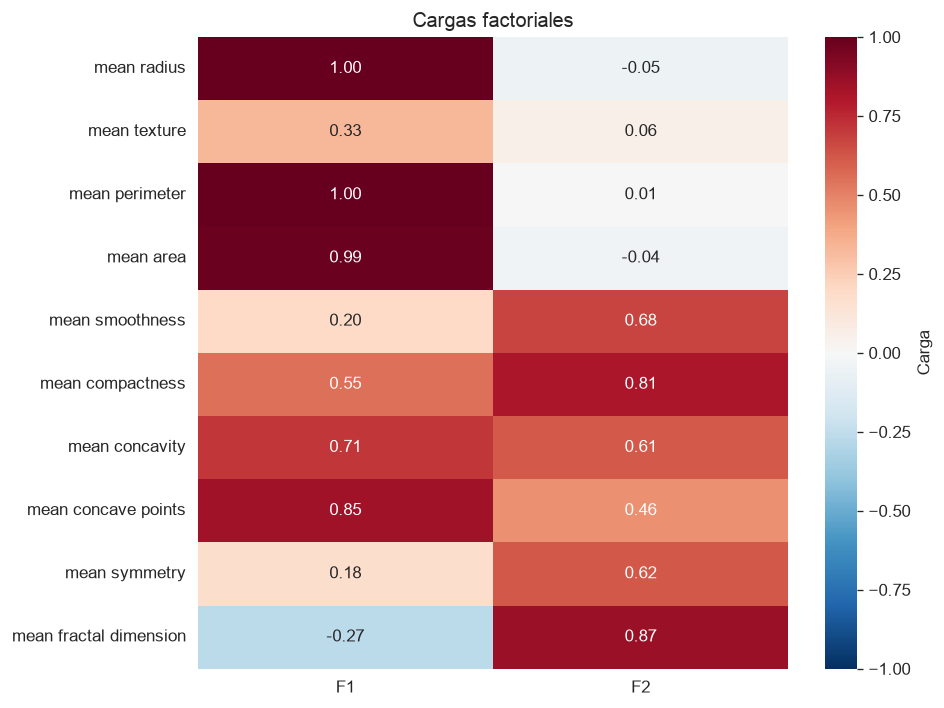


Comunalidades (varianza explicada por factores):
mean radius               0.999
mean texture              0.112
mean perimeter            1.000
mean area                 0.976
mean smoothness           0.502
mean compactness          0.967
mean concavity            0.884
mean concave points       0.929
mean symmetry             0.415
mean fractal dimension    0.821
dtype: float64


In [10]:
# Heatmap de cargas factoriales
plt.figure(figsize=(8, 6))
sns.heatmap(cargas_fa, annot=True, cmap='RdBu_r', center=0,
            vmin=-1, vmax=1, fmt='.2f', cbar_kws={'label': 'Carga'})
plt.title('Cargas factoriales')
plt.tight_layout()
plt.show()

# Comunalidades (proporción de varianza explicada por los factores)
comunalidades = (cargas_fa ** 2).sum(axis=1)
print("\nComunalidades (varianza explicada por factores):")
print(comunalidades.round(3))

## Ejemplo 3. Factores y regresión logística

La regresión logística permite clasificar observaciones. Para evaluar los dos modelos, separo primero los datos de entrenamiento y prueba. La estandarización y el análisis factorial se ajustan únicamente con el entrenamiento, de modo que la prueba evalúe casos que el modelo no usó al aprender.

In [11]:
# EJEMPLO 3: FACTORES Y REGRESIÓN LOGÍSTICA
# Primero separamos las observaciones; después ajustamos las transformaciones.
X_train_raw, X_test_raw, y_train, y_test = train_test_split(
    X_fa, y_bc, test_size=0.3, random_state=42, stratify=y_bc
)
scaler_bc = StandardScaler().fit(X_train_raw)
X_train_orig = scaler_bc.transform(X_train_raw)
X_test_orig = scaler_bc.transform(X_test_raw)

modelo_orig = LogisticRegression(max_iter=1000, random_state=42)
modelo_orig.fit(X_train_orig, y_train)
acc_orig = accuracy_score(y_test, modelo_orig.predict(X_test_orig))

pca_bc_train = PCA().fit(X_train_orig)
n_factores_train = int((pca_bc_train.explained_variance_ > 1).sum())
fa_bc_train = FactorAnalysis(n_components=n_factores_train, random_state=42)
X_train_fa = fa_bc_train.fit_transform(X_train_orig)
X_test_fa = fa_bc_train.transform(X_test_orig)
modelo_fa = LogisticRegression(max_iter=1000, random_state=42)
modelo_fa.fit(X_train_fa, y_train)
acc_fa = accuracy_score(y_test, modelo_fa.predict(X_test_fa))

print("Comparación del ejemplo en los mismos datos de prueba")
print(f"Variables originales ({X_fa.shape[1]}): {acc_orig:.2%}")
print(f"Factores ({n_factores_train}): {acc_fa:.2%}")


Comparación del ejemplo en los mismos datos de prueba
Variables originales (10): 91.81%
Factores (2): 91.81%


## Instrucciones de la actividad

In [12]:
# ============================================================
# ACTIVIDAD: REPLICAR TODO CON EL DATASET DE VINOS
# ============================================================

print("ACTIVIDAD: Correlación Canónica y Análisis Factorial")
print("=" * 55)
print("\nDataset: Wine (load_wine)")
print("\nInstrucciones:")
print("\n1. CCA:")
print("   - Definir dos conjuntos de variables de vino.")
print("     Ejemplo: X = alcalinidad, magnesio, fenoles totales")
print("              Y = alcohol, ácido málico, ceniza")
print("   - Estandarizar ambos conjuntos")
print("   - Ajustar CCA con 2 componentes")
print("   - Reportar correlaciones canónicas")
print("   - Graficar pares canónicos")
print()
print("2. Análisis Factorial:")
print("   - Seleccionar 8-10 variables del dataset")
print("   - Estandarizar")
print("   - Scree plot para elegir número de factores")
print("   - Extraer factores y reportar cargas")
print("   - Interpretar los factores")
print()
print("3. FA + Regresión:")
print("   - Binificar la variable Clase (ej. 0 vs resto)")
print("   - Ajustar regresión logística con variables originales")
print("   - Ajustar regresión logística con scores factoriales")
print("   - Comparar accuracy de ambos modelos")

ACTIVIDAD: Correlación Canónica y Análisis Factorial

Dataset: Wine (load_wine)

Instrucciones:

1. CCA:
   - Definir dos conjuntos de variables de vino.
     Ejemplo: X = alcalinidad, magnesio, fenoles totales
              Y = alcohol, ácido málico, ceniza
   - Estandarizar ambos conjuntos
   - Ajustar CCA con 2 componentes
   - Reportar correlaciones canónicas
   - Graficar pares canónicos

2. Análisis Factorial:
   - Seleccionar 8-10 variables del dataset
   - Estandarizar
   - Scree plot para elegir número de factores
   - Extraer factores y reportar cargas
   - Interpretar los factores

3. FA + Regresión:
   - Binificar la variable Clase (ej. 0 vs resto)
   - Ajustar regresión logística con variables originales
   - Ajustar regresión logística con scores factoriales
   - Comparar accuracy de ambos modelos


## Actividad con vinos

### 1. Cargar y revisar los datos

Uso el conjunto `Wine`, incluido en scikit-learn. Contiene **178 vinos, 13 mediciones y tres clases**. La clase es la categoría que voy a estudiar; no representa una calificación de calidad. Para el análisis factorial selecciono ocho mediciones, como indica la actividad.

In [13]:
wine = load_wine()
X_wine = pd.DataFrame(wine.data, columns=wine.feature_names)
y_wine = pd.Series(wine.target, name='Clase')
df_wine = pd.concat([X_wine, y_wine], axis=1)

nombres = {
    'alcohol': 'Alcohol',
    'malic_acid': 'Ácido málico',
    'ash': 'Ceniza',
    'alcalinity_of_ash': 'Alcalinidad de la ceniza',
    'magnesium': 'Magnesio',
    'total_phenols': 'Fenoles totales',
    'flavanoids': 'Flavonoides',
    'nonflavanoid_phenols': 'Fenoles no flavonoides'
}

print(f'Vinos: {len(df_wine)} | Mediciones: {X_wine.shape[1]}')
print(f'Datos faltantes: {df_wine.isna().sum().sum()}')
display(df_wine.head())
display(y_wine.value_counts().sort_index().rename_axis('Clase').to_frame('Cantidad'))

Vinos: 178 | Mediciones: 13
Datos faltantes: 0


,alcohol,malic_acid,ash,alcalinity_of_ash,magnesium,total_phenols,flavanoids,nonflavanoid_phenols,proanthocyanins,color_intensity,hue,od280/od315_of_diluted_wines,proline,Clase
0,14.23,1.71,2.43,15.6,127.0,2.80,3.06,0.28,2.29,5.64,1.04,3.92,1065.0,0
1,13.20,1.78,2.14,11.2,100.0,2.65,2.76,0.26,1.28,4.38,1.05,3.40,1050.0,0
2,13.16,2.36,2.67,18.6,101.0,2.80,3.24,0.30,2.81,5.68,1.03,3.17,1185.0,0
3,14.37,1.95,2.50,16.8,113.0,3.85,3.49,0.24,2.18,7.80,0.86,3.45,1480.0,0
4,13.24,2.59,2.87,21.0,118.0,2.80,2.69,0.39,1.82,4.32,1.04,2.93,735.0,0


,Cantidad
Clase,
0,59
1,71
2,48


### 2. Correlación canónica (CCA)

Formo los grupos propuestos en la plantilla:

- **Grupo X:** alcalinidad de la ceniza, magnesio y fenoles totales.
- **Grupo Y:** alcohol, ácido málico y ceniza.

Estandarizo cada grupo para que las diferencias de escala no dominen el análisis. Calculo dos pares de variables canónicas: U1 con V1 y U2 con V2. Cada una es una combinación de las mediciones de su grupo.

In [14]:
vars_x_w = ['alcalinity_of_ash', 'magnesium', 'total_phenols']
vars_y_w = ['alcohol', 'malic_acid', 'ash']
X_cca_w = df_wine[vars_x_w].to_numpy()
Y_cca_w = df_wine[vars_y_w].to_numpy()

X_cca_w_std = StandardScaler().fit_transform(X_cca_w)
Y_cca_w_std = StandardScaler().fit_transform(Y_cca_w)
cca_w = CCA(n_components=2, max_iter=1000)
U_w, V_w = cca_w.fit_transform(X_cca_w_std, Y_cca_w_std)
rho_w = np.array([np.corrcoef(U_w[:, i], V_w[:, i])[0, 1] for i in range(2)])

tabla_cca_w = pd.DataFrame({
    'Par canónico': ['U1 con V1', 'U2 con V2'],
    'Correlación': rho_w,
    'Correlación al cuadrado': rho_w ** 2
})
display(tabla_cca_w.round(4))

,Par canónico,Correlación,Correlación al cuadrado
0,U1 con V1,0.6592,0.4346
1,U2 con V2,0.5216,0.2720


In [15]:
# Pesos: coeficientes que utiliza CCA para formar las combinaciones.
pesos_x_w = pd.DataFrame(cca_w.x_weights_,
    index=[nombres[v] for v in vars_x_w], columns=['U1', 'U2'])
pesos_y_w = pd.DataFrame(cca_w.y_weights_,
    index=[nombres[v] for v in vars_y_w], columns=['V1', 'V2'])
print('Pesos del grupo X:')
display(pesos_x_w.round(4))
print('Pesos del grupo Y:')
display(pesos_y_w.round(4))

# Cargas: correlaciones de las mediciones con las variables canónicas.
cargas_x_w = pd.DataFrame(
    [[np.corrcoef(X_cca_w_std[:, j], U_w[:, i])[0, 1] for i in range(2)]
     for j in range(len(vars_x_w))],
    index=[nombres[v] for v in vars_x_w], columns=['U1', 'U2'])
cargas_y_w = pd.DataFrame(
    [[np.corrcoef(Y_cca_w_std[:, j], V_w[:, i])[0, 1] for i in range(2)]
     for j in range(len(vars_y_w))],
    index=[nombres[v] for v in vars_y_w], columns=['V1', 'V2'])
print('Cargas del grupo X:')
display(cargas_x_w.round(4))
print('Cargas del grupo Y:')
display(cargas_y_w.round(4))

Pesos del grupo X:


,U1,U2
Alcalinidad de la ceniza,0.9880,-0.0834
Magnesio,0.1544,0.5278
Fenoles totales,0.0011,0.8453


Pesos del grupo Y:


,V1,V2
Alcohol,-0.5683,0.5025
Ácido málico,0.3243,-0.5910
Ceniza,0.7562,0.6310


Cargas del grupo X:


,U1,U2
Alcalinidad de la ceniza,0.9877,-0.1077
Magnesio,0.0732,0.6836
Fenoles totales,-0.2869,0.8378


Cargas del grupo Y:


,V1,V2
Alcohol,-0.4064,0.5988
Ácido málico,0.4246,-0.4558
Ceniza,0.7415,0.6454


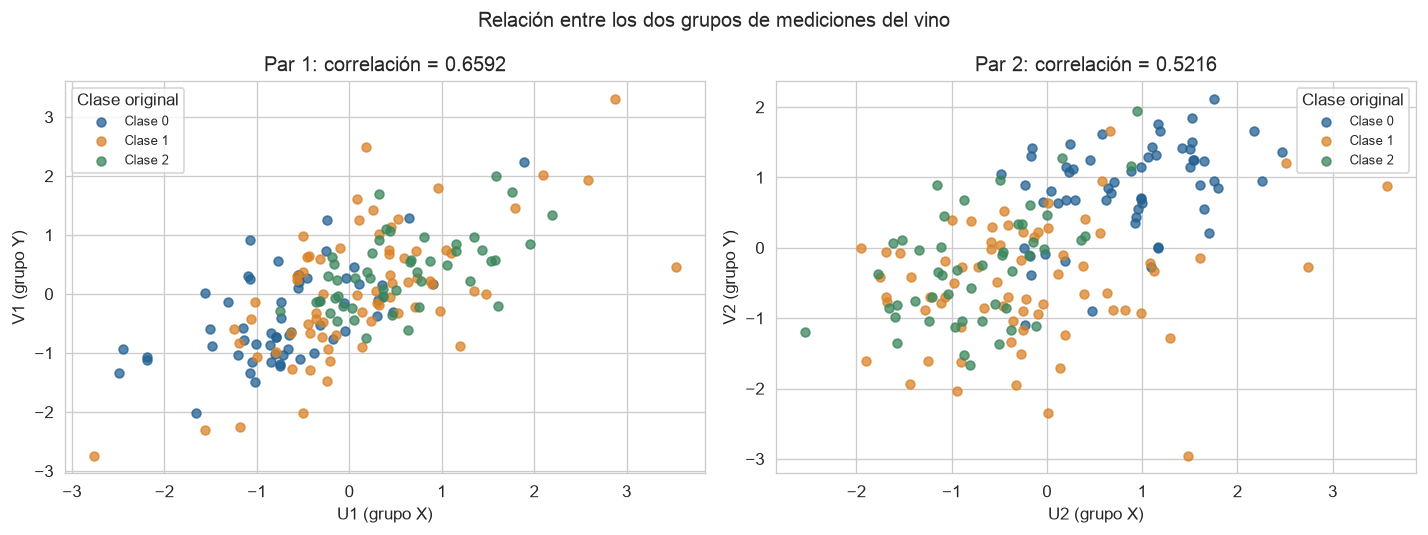

In [16]:
fig, axes = plt.subplots(1, 2, figsize=(12, 4.5))
colores = ['#236192', '#d98228', '#39855b']
for i, ax in enumerate(axes):
    for clase, color in enumerate(colores):
        mascara = y_wine.to_numpy() == clase
        ax.scatter(U_w[mascara, i], V_w[mascara, i],
                   color=color, label=f'Clase {clase}', alpha=0.75, s=28)
    ax.set_xlabel(f'U{i+1} (grupo X)')
    ax.set_ylabel(f'V{i+1} (grupo Y)')
    ax.set_title(f'Par {i+1}: correlación = {rho_w[i]:.4f}')
    ax.legend(title='Clase original', fontsize=8)
fig.suptitle('Relación entre los dos grupos de mediciones del vino')
plt.tight_layout()
plt.show()

**Interpretación.** El primer par tiene una correlación de **0.6592** y el segundo de **0.5216**. En ambos observo una relación positiva entre las combinaciones de los dos grupos, más fuerte en el primer par. En las gráficas los puntos tienden a subir juntos, aunque presentan dispersión.

Sus correlaciones al cuadrado son **0.4346** y **0.2720**. Estos valores describen la relación de cada par de combinaciones; no son el porcentaje de variación explicado de todas las mediciones del vino. Los colores permiten observar las clases, pero no se usan para ajustar CCA. Estos resultados muestran asociación y no demuestran que una característica cause otra.

### 3. Análisis factorial: selección y estandarización

Selecciono ocho variables: alcohol, ácido málico, ceniza, alcalinidad de la ceniza, magnesio, fenoles totales, flavonoides y fenoles no flavonoides. Las estandarizo para trabajar con escalas comparables.

In [17]:
vars_fa_w = ['alcohol', 'malic_acid', 'ash', 'alcalinity_of_ash',
             'magnesium', 'total_phenols', 'flavanoids', 'nonflavanoid_phenols']
X_fa_w = df_wine[vars_fa_w].to_numpy()
X_fa_w_std = StandardScaler().fit_transform(X_fa_w)
print(f'Matriz para el análisis factorial: {X_fa_w_std.shape[0]} vinos y {X_fa_w_std.shape[1]} variables.')

Matriz para el análisis factorial: 178 vinos y 8 variables.


### 4. Número de factores

Uso un PCA como apoyo para construir el gráfico de sedimentación y aplicar la regla de Kaiser: conservar las componentes con eigenvalor mayor que 1. Esta regla orienta la cantidad de factores que voy a extraer; después ajusto un análisis factorial.

,Componente,Eigenvalor,Varianza PCA (%),Acumulada PCA (%)
0,1,2.958,36.767,36.767
1,2,1.644,20.432,57.199
2,3,1.104,13.727,70.927
3,4,0.829,10.304,81.231
4,5,0.658,8.174,89.405
5,6,0.448,5.564,94.968
6,7,0.284,3.533,98.501
7,8,0.121,1.499,100.000


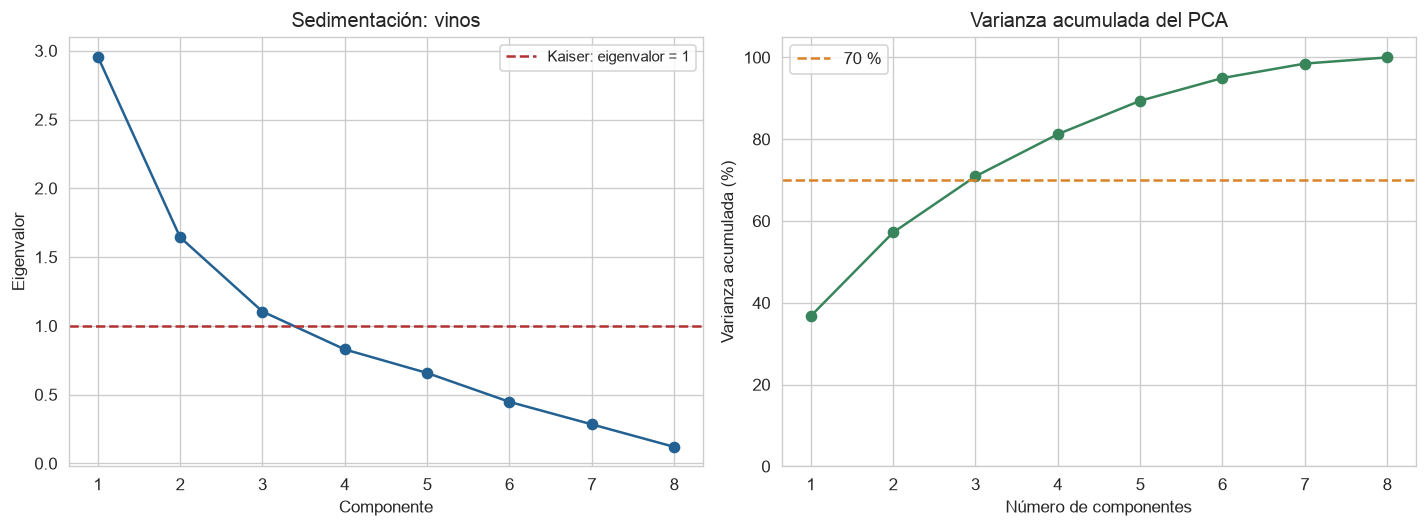

Factores seleccionados: 3


In [18]:
pca_w = PCA().fit(X_fa_w_std)
eigenvalues_w = pca_w.explained_variance_
varianza_acum_w = np.cumsum(pca_w.explained_variance_ratio_)
n_fact_w = int((eigenvalues_w > 1).sum())
tabla_eigen_w = pd.DataFrame({
    'Componente': np.arange(1, len(eigenvalues_w) + 1),
    'Eigenvalor': eigenvalues_w,
    'Varianza PCA (%)': pca_w.explained_variance_ratio_ * 100,
    'Acumulada PCA (%)': varianza_acum_w * 100
})
display(tabla_eigen_w.round(3))

fig, axes = plt.subplots(1, 2, figsize=(12, 4.5))
componentes_w = np.arange(1, len(eigenvalues_w) + 1)
axes[0].plot(componentes_w, eigenvalues_w, 'o-', color='#236192')
axes[0].axhline(1, color='#b33131', linestyle='--', label='Kaiser: eigenvalor = 1')
axes[0].set(xlabel='Componente', ylabel='Eigenvalor', title='Sedimentación: vinos')
axes[0].legend(fontsize=9)
axes[1].plot(componentes_w, varianza_acum_w * 100, 'o-', color='#39855b')
axes[1].axhline(70, color='#d98228', linestyle='--', label='70 %')
axes[1].set(xlabel='Número de componentes', ylabel='Varianza acumulada (%)',
            title='Varianza acumulada del PCA', ylim=(0, 105))
axes[1].legend()
for ax in axes:
    ax.set_xticks(componentes_w)
plt.tight_layout()
plt.show()
print(f'Factores seleccionados: {n_fact_w}')

**Decisión.** Conservo **tres factores**, porque los tres primeros eigenvalores son mayores que 1: **2.958, 1.644 y 1.104**. El cuarto ya es menor que 1. La curva empieza a aplanarse después de las primeras componentes, lo que apoya esta elección.

Las tres primeras componentes del PCA acumulan **70.93 %** de la varianza. Este porcentaje corresponde al PCA usado como guía; el análisis factorial tiene su propio resultado.

### 5. Extracción e interpretación de los factores

Ajusto el análisis factorial con tres factores y uso una rotación **varimax**, que facilita reconocer las variables relacionadas con cada factor. Para presentar las cargas, oriento cada factor de modo que su carga más grande en valor absoluto sea positiva. Cambiar todo el signo de un factor no cambia lo que representa.

,F1,F2,F3
Alcohol,0.168,0.092,0.821
Ácido málico,-0.437,0.222,0.141
Ceniza,0.092,0.904,0.138
Alcalinidad de la ceniza,-0.334,0.581,-0.372
Magnesio,0.180,0.221,0.296
Fenoles totales,0.867,0.035,0.166
Flavonoides,0.978,0.014,0.087
Fenoles no flavonoides,-0.540,0.267,-0.120


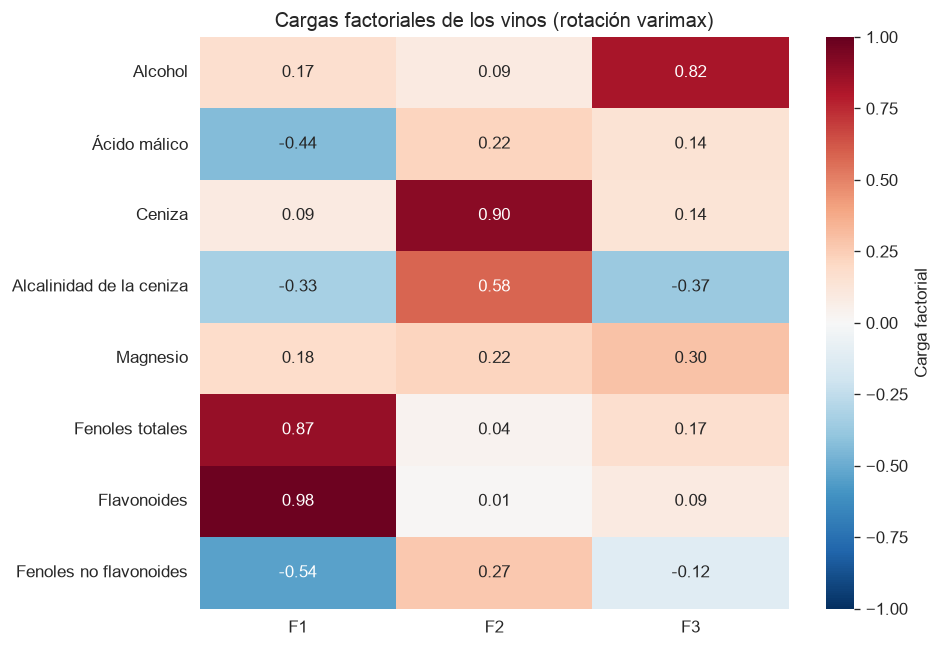

,Comunalidad
Alcohol,0.711
Ácido málico,0.260
Ceniza,0.845
Alcalinidad de la ceniza,0.588
Magnesio,0.169
Fenoles totales,0.781
Flavonoides,0.964
Fenoles no flavonoides,0.377


Varianza de las ocho variables representada por los factores: 58.69 %


In [19]:
fa_w = FactorAnalysis(n_components=n_fact_w, rotation='varimax', random_state=42)
scores_w = fa_w.fit_transform(X_fa_w_std)

# Orientación de signos solo para facilitar la lectura.
matriz_cargas_w = fa_w.components_.T.copy()
filas_max_w = np.argmax(np.abs(matriz_cargas_w), axis=0)
signos_w = np.sign(matriz_cargas_w[filas_max_w, np.arange(n_fact_w)])
signos_w[signos_w == 0] = 1
matriz_cargas_w *= signos_w
scores_w *= signos_w
cargas_w = pd.DataFrame(matriz_cargas_w,
    index=[nombres[v] for v in vars_fa_w],
    columns=[f'F{i+1}' for i in range(n_fact_w)])
display(cargas_w.round(3))

plt.figure(figsize=(8, 5.5))
sns.heatmap(cargas_w, annot=True, fmt='.2f', cmap='RdBu_r', center=0,
            vmin=-1, vmax=1, cbar_kws={'label': 'Carga factorial'})
plt.title('Cargas factoriales de los vinos (rotación varimax)')
plt.ylabel('')
plt.tight_layout()
plt.show()

comunalidades_w = (cargas_w ** 2).sum(axis=1)
display(comunalidades_w.to_frame('Comunalidad').round(3))
porcentaje_fa_w = comunalidades_w.mean() * 100
print(f'Varianza de las ocho variables representada por los factores: {porcentaje_fa_w:.2f} %')

**Factor 1: compuestos fenólicos.** Las cargas más altas son las de flavonoides (**0.978**) y fenoles totales (**0.867**). Los fenoles no flavonoides tienen una carga negativa de **−0.540**. Por eso interpreto este factor como una combinación de características fenólicas, con una relación en sentido contrario para los fenoles no flavonoides.

**Factor 2: características de la ceniza.** Destacan la ceniza (**0.904**) y la alcalinidad de la ceniza (**0.582**). Este factor resume principalmente esas dos mediciones.

**Factor 3: alcohol.** Su carga principal es la del alcohol (**0.821**). La alcalinidad de la ceniza aparece en sentido contrario (**−0.372**), aunque su relación es menor. Por eso lo identifico principalmente con el contenido de alcohol.

Las **comunalidades** indican qué parte de la variación de cada variable representan los factores. Los flavonoides quedan bien representados (**0.964**), mientras que el magnesio queda poco representado (**0.169**). En conjunto, los factores representan aproximadamente **58.69 %** de la varianza de las ocho variables estandarizadas. Esto indica que simplifican los datos, pero también dejan información fuera.

### 6. Análisis factorial y regresión logística

Convierto la clase en una variable binaria: **1 si el vino pertenece a la clase 0 y 0 si pertenece a las clases 1 o 2**. Divido los datos en 70 % para entrenamiento y 30 % para prueba, conservando la proporción de ambos grupos.

Comparo una regresión logística con las ocho variables y otra con las puntuaciones factoriales, que indican la posición de cada vino en los factores. Para que la comparación sea válida, uso exactamente las mismas observaciones en ambos modelos. Ajusto el escalador, la selección del número de factores y el análisis factorial solo con el entrenamiento; después transformo los datos de prueba con esos ajustes.

In [20]:
df_wine['Clase_bin'] = (df_wine['Clase'] == 0).astype(int)
y_bin_w = df_wine['Clase_bin'].to_numpy()
X_tr_raw_w, X_te_raw_w, y_tr_w, y_te_w = train_test_split(
    X_fa_w, y_bin_w, test_size=0.3, random_state=42, stratify=y_bin_w
)

scaler_modelo_w = StandardScaler().fit(X_tr_raw_w)
X_tr_w = scaler_modelo_w.transform(X_tr_raw_w)
X_te_w = scaler_modelo_w.transform(X_te_raw_w)

m_orig_w = LogisticRegression(max_iter=1000, random_state=42)
m_orig_w.fit(X_tr_w, y_tr_w)
pred_orig_w = m_orig_w.predict(X_te_w)
acc_orig_w = accuracy_score(y_te_w, pred_orig_w)

# Volvemos a elegir y ajustar los factores únicamente con entrenamiento.
pca_train_w = PCA().fit(X_tr_w)
n_fact_train_w = int((pca_train_w.explained_variance_ > 1).sum())
fa_train_w = FactorAnalysis(n_components=n_fact_train_w,
                           rotation='varimax', random_state=42)
X_tr_wf = fa_train_w.fit_transform(X_tr_w)
X_te_wf = fa_train_w.transform(X_te_w)
m_fa_w = LogisticRegression(max_iter=1000, random_state=42)
m_fa_w.fit(X_tr_wf, y_tr_w)
pred_fa_w = m_fa_w.predict(X_te_wf)
acc_fa_w = accuracy_score(y_te_w, pred_fa_w)

comparacion_w = pd.DataFrame({
    'Modelo': ['Variables originales', 'Factores'],
    'Número de predictores': [len(vars_fa_w), n_fact_train_w],
    'Aciertos': [int((pred_orig_w == y_te_w).sum()), int((pred_fa_w == y_te_w).sum())],
    'Casos de prueba': [len(y_te_w), len(y_te_w)],
    'Accuracy (%)': [acc_orig_w * 100, acc_fa_w * 100]
})
print(f'Entrenamiento: {len(y_tr_w)} vinos | Prueba: {len(y_te_w)} vinos')
print(f'Factores seleccionados con entrenamiento: {n_fact_train_w}')
display(comparacion_w.round(2))
print(f'Diferencia: {(acc_orig_w - acc_fa_w) * 100:.2f} puntos porcentuales.')

Entrenamiento: 124 vinos | Prueba: 54 vinos
Factores seleccionados con entrenamiento: 3


,Modelo,Número de predictores,Aciertos,Casos de prueba,Accuracy (%)
0,Variables originales,8,51,54,94.44
1,Factores,3,49,54,90.74


Diferencia: 3.70 puntos porcentuales.


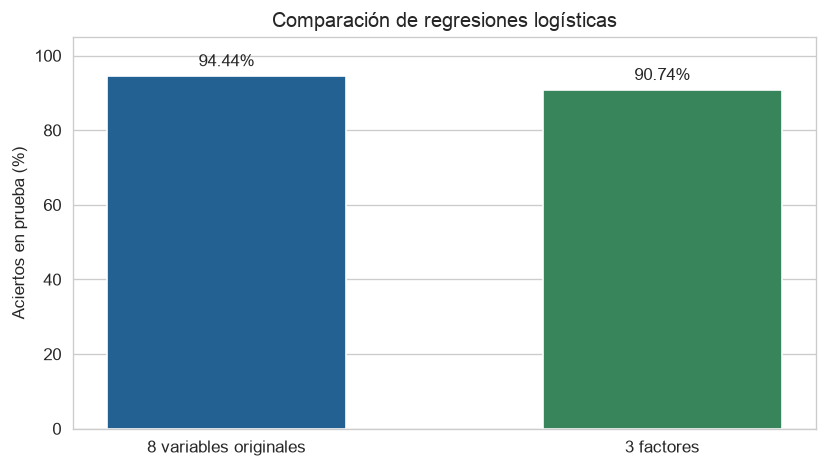

In [21]:
fig, ax = plt.subplots(figsize=(7, 4))
barras = ax.bar(['8 variables originales', f'{n_fact_train_w} factores'],
                [acc_orig_w * 100, acc_fa_w * 100], color=['#236192', '#39855b'], width=0.55)
ax.bar_label(barras, labels=[f'{acc_orig_w:.2%}', f'{acc_fa_w:.2%}'], padding=4)
ax.set(ylabel='Aciertos en prueba (%)', ylim=(0, 105),
       title='Comparación de regresiones logísticas')
ax.grid(axis='x', visible=False)
plt.tight_layout()
plt.show()

**Comparación.** El modelo con ocho variables originales obtiene **94.44 %** de accuracy, es decir, **51 aciertos de 54 vinos**. El modelo con tres factores obtiene **90.74 %**, con **49 aciertos de 54**. La diferencia es de **3.70 puntos porcentuales**, equivalente a dos vinos.

El análisis factorial reduce los predictores de **ocho a tres**, una reducción de **62.5 %**, pero en esta prueba pierde algo de precisión. Si mi prioridad fuera acertar más, elegiría el modelo con las variables originales. Si necesitara trabajar con menos predictores, consideraría el modelo con factores. Esta comparación corresponde a una sola división de datos; no asegura que la diferencia sea igual en todas las muestras.

### 7. Conclusión

Con CCA encontré que los dos grupos de mediciones del vino están relacionados: el primer par canónico presenta una correlación de **0.6592** y el segundo de **0.5216**. Con el análisis factorial resumí ocho variables en tres factores asociados principalmente con compuestos fenólicos, características de la ceniza y alcohol.

Al clasificar los vinos de la clase 0 frente al resto, el modelo con las variables originales tuvo más aciertos. Considero que los factores ayudan a simplificar e interpretar los datos, aunque esa simplificación puede dejar fuera información útil para clasificar.

